Here is a simple example code for device fitting using a multilayer perceptron model.
This code demonstrates the implementation of a Multilayer Perceptron (MLP) using PyTorch, a popular deep learning framework. Let's break down the key components of this code.

In [155]:
import os
import sys
import json

import torch
import torch.nn as nn
from torchvision import transforms, datasets, utils
import matplotlib.pyplot as plt
import numpy as np
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import pandas as pd
from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


from torch.utils.data import TensorDataset, DataLoader
from torch_geometric.data import Data

from model import MLP

This code defines a Multilayer Perceptron (MLP) neural network using PyTorch's nn.Module.
self.features defines the sequential layers of the neural network using nn.Sequential().
Here we define a 3-layer MLP.
nn.Linear(3, 30): The first layer consists of 3 input neurons and 30 neurons in the hidden layer. It performs a linear transformation (fully connected layer) from 3 input features to 30 neurons.
nn.ReLU(inplace=True): Applies a Rectified Linear Unit (ReLU) activation function to introduce non-linearity after the first linear transformation.
nn.Linear(30, 10): The second layer comprises 30 input neurons and 10 neurons in the hidden layer, followed by another ReLU activation.
nn.Linear(10,1): The final layer has 10 input neurons and 1 output neuron, producing the final output of the MLP.

The forward method defines the forward pass through the network.

In [156]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.features = nn.Sequential(
            nn.Linear(7, 30), # 7 input, first layer 30 neurons, using linear transformation
            nn.ReLU(inplace=True),
            nn.Linear(30, 10),  # second layer 10 neurons using rectified linear unit
            nn.ReLU(inplace=True),
            nn.Linear(10,1), # 1 output reduce to the final output
        )


    def forward(self, x):
        x = self.features(x)
        x = x.squeeze(-1)
        return x

The code snippet demonstrates the selection of the computational device for running the MLP (Multilayer Perceptron) network.
Device Allocation:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu"): This line of code assigns the computational device to the variable device. If a GPU is available, it selects the GPU (cuda:0); otherwise, it defaults to the CPU (cpu).
Printing Device Information:
print("using {} device.".format(device)): This prints a message indicating the device being utilized for computation.

In [157]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("using {} device.".format(device))

using cpu device.


The code snippet demonstrates reading data from an Excel file into a Python environment using the Pandas library.
Excel File Import:
excel_file = '../data/carbon/pfet.xlsx': Specifies the file path (pfet.xlsx) of the Excel file containing the data.
Pandas DataFrame Creation:
df = pd.read_excel(excel_file): Utilizes Pandas' read_excel function to load the Excel file into a Pandas DataFrame named df. This function reads the Excel file's contents and stores them in a tabular format.
Data Verification:
print(df.head()): Displays the first few rows of the loaded DataFrame using the head() method. This step helps verify the successful import of data by showing the initial rows of the DataFrame, ensuring that the data is correctly read and structured.

In [158]:
#Excel File Import
csv_file = 'Silicon_Dataset.csv'
df = pd.read_csv(csv_file)
df = df.apply(pd.to_numeric)

print(df.head())

    Lg  Lch    Tox          Nsub         PeakV  Vds       Vgs            Id
0  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -1.000000  3.220000e-16
1  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.974747  3.220000e-16
2  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.949495  3.210000e-16
3  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.924242  3.230000e-16
4  0.1  0.2  0.008  1.000000e+18  6.000000e+20  0.2 -0.898990  3.230000e-16


This code snippet focuses on data preparation steps necessary before training the Multilayer Perceptron (MLP) model.
Input and Output Extraction:
Specifies the columns representing input features based on their column names in the dataset.
Defines the output column ('ids') indicating the target output (e.g., current) from the dataset.
Conversion to PyTorch Tensors:
Converts the selected input columns and output column into PyTorch tensors. This step transforms the input data into a format suitable for feeding into the neural network.
Data Transformation:
Take the logarithm of the output data to narrow the data range. This transformation might be employed to normalize or preprocess the output data, ensuring better convergence during training or meeting specific requirements of the model.

In [159]:

# Assuming 'df' is your DataFrame and 'Id' is the target column
input_columns = ['Lg', 'Lch', 'Tox', 'Nsub', 'PeakV', 'Vds', 'Vgs']
output_column = 'Id'

# Prepare the data
X = df[input_columns].values
Y = df[output_column].values


This section of code mainly used do feature selection and show the importance of each different feature's relationship and importance between the factors.

In [160]:
# # Splitting the data into train and test sets
# X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

# # Train a Random Forest Regressor model
# rf_model = RandomForestRegressor(random_state=42)
# rf_model.fit(X_train, Y_train)

# # Compute the baseline Mean Squared Error
# Y_pred = rf_model.predict(X_test)
# baseline_mse = mean_squared_error(Y_test, Y_pred)
# print(f"Baseline Mean Squared Error: {baseline_mse:.4f}")

# # Get feature importances
# feature_importances = rf_model.feature_importances_

# # Display feature importance
# feature_names = X_test.columns.tolist()
# importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': feature_importances})
# importance_df = importance_df.sort_values(by='Importance', ascending=False)

# print(importance_df)

# # Plot feature importance
# plt.figure(figsize=(10, 6))
# plt.barh(importance_df['Feature'], importance_df['Importance'])
# plt.xlabel('Importance')
# plt.ylabel('Feature')
# plt.title('Feature Importance')
# plt.gca().invert_yaxis()
# plt.show()

This section of the code snippet focuses on partitioning the available data into separate sets for training and testing the MLP (Multilayer Perceptron) model.
Splitting the Dataset:
These calculations aim to appropriately divide the dataset into two distinct portions:
Training Set: Comprising 90% of the data, reserved for training the MLP model. It includes input-output pairs used to optimize the model's parameters.
Testing Set: Consisting of the remaining 10% of the data. This set remains unseen during training and is employed solely for evaluating the model's performance on unseen data, assessing its generalization capability.

In [ ]:

# Pick the first 10000 samples
sample_num = 30000
X = X[:sample_num]
Y = Y[:sample_num]

# Normalize the data
scaler_X = StandardScaler()
scaler_Y = StandardScaler()
X = scaler_X.fit_transform(X)
Y = scaler_Y.fit_transform(Y.reshape(-1, 1)).flatten()

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)



In [162]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42)


This part of the code is responsible for constructing specific datasets—both for training and testing the MLP (Multilayer Perceptron) model.
Constructs the training dataset and forms the testing dataset (test_dataset) by packing the remaining input-output pairs not included in the training set.

In [163]:
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)


This section of the code focuses on setting up data loaders, essential components used to manage and facilitate the training and testing processes within the MLP.
Defining Batch Size:
batch_size = 32: Specifies the batch size, indicating the number of samples that the model will process in each iteration during training or testing. It's a hyperparameter selected to balance computational efficiency and model learning.
Creating Training Data Loader:
Constructs a training data loader (train_loader) using PyTorch's DataLoader. This loader takes the previously created training dataset (train_dataset) and organizes it into batches of size batch_size. The shuffle=True parameter randomly shuffles the samples within each batch, enhancing model learning by providing diverse sample sequences.
Creating Testing Data Loader:
Constructs a testing data loader (test_loader) in a similar manner to the training loader. It takes the testing dataset (test_dataset) and organizes it into batches of the specified batch_size.

In [ ]:
# creating data loader
train_dataset = torch.utils.data.TensorDataset(X_train, y_train)
test_dataset = torch.utils.data.TensorDataset(X_test, y_test)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32)


using 4500 data for training, 500 data for validation.


# MLP Learning

In [ ]:
# Assuming MLP is defined elsewhere
# from model import MLP

net = MLP().to(device)
loss_function = nn.MSELoss(reduction="mean")
optimizer = optim.Adam(net.parameters(), lr=0.02)




In [166]:
# Training loop
epochs = 100
save_path = './MLP.pth'
best_val_mse = float('inf')
train_steps = len(train_loader)
val_mse_list = []  # List to store val_mse values

for epoch in range(epochs):
    # Train
    net.train()
    running_loss = 0.0
    train_bar = tqdm(train_loader, file=sys.stdout)
    for step, data in enumerate(train_bar):
        input_vari, output_tar = data
        optimizer.zero_grad()
        outputs = net(input_vari.to(device))
        loss = loss_function(outputs, output_tar.to(device))
        loss.backward()
        optimizer.step()

        # Print statistics
        running_loss += loss.item()
        train_bar.desc = "train epoch[{}/{}] loss:{:.3f}".format(epoch + 1, epochs, loss)
    
    # Validate
    net.eval()
    mse_sum = 0.0
    with torch.no_grad():
        val_bar = tqdm(test_loader, file=sys.stdout)
        for val_data in val_bar:
            val_input, val_output = val_data
            outputs = net(val_input.to(device))
            mse = loss_function(outputs, val_output.to(device))
            mse_sum += mse.item() * val_input.size(0)

    val_mse = mse_sum / len(test_loader.dataset)
    val_mse_list.append(val_mse)  # Store val_mse value
    print('[epoch %d] train_loss: %.3f  val_mse: %.6f' %
          (epoch + 1, running_loss / train_steps, val_mse))

    # Save the best model
    if val_mse < best_val_mse:
        best_val_mse = val_mse
        torch.save(net.state_dict(), save_path)



100%|██████████| 63/63 [00:00<00:00, 1591.29it/s]
[epoch 1] train_loss: 0.123  val_mse: 0.258418
100%|██████████| 63/63 [00:00<00:00, 1850.07it/s]
[epoch 2] train_loss: 0.030  val_mse: 0.007917
100%|██████████| 63/63 [00:00<00:00, 2096.14it/s]
[epoch 3] train_loss: 0.010  val_mse: 0.007429
100%|██████████| 63/63 [00:00<00:00, 2339.02it/s]
[epoch 4] train_loss: 0.009  val_mse: 0.019373
100%|██████████| 63/63 [00:00<00:00, 2405.08it/s]
[epoch 5] train_loss: 0.007  val_mse: 0.007528
100%|██████████| 63/63 [00:00<00:00, 2207.33it/s]
[epoch 6] train_loss: 0.007  val_mse: 0.004485
100%|██████████| 63/63 [00:00<00:00, 2321.73it/s]
[epoch 7] train_loss: 0.006  val_mse: 0.005424
100%|██████████| 63/63 [00:00<00:00, 2338.96it/s]
[epoch 8] train_loss: 0.013  val_mse: 0.010831
100%|██████████| 63/63 [00:00<00:00, 2319.33it/s]
[epoch 9] train_loss: 0.006  val_mse: 0.014210
100%|██████████| 63/63 [00:00<00:00, 2311.76it/s]
[epoch 10] train_loss: 0.007  val_mse: 0.012954
100%|██████████| 63/63 [00:00

The code below will illustrate the relationship between validation MSE and epoch.

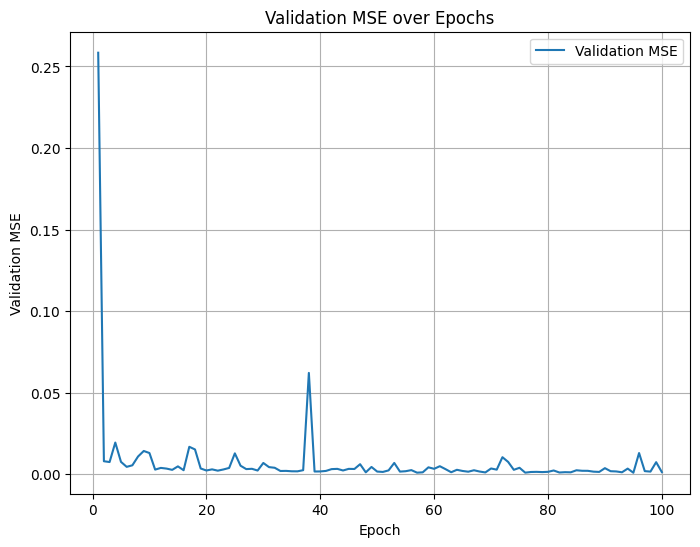

In [167]:
# Plot the change of val_mse over epochs
plt.figure(figsize=(8, 6))
plt.plot(range(1, epochs + 1), val_mse_list, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.title('Validation MSE over Epochs')
plt.legend()
plt.grid(True)
plt.show()